# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
from aitlas.datasets import HephaestusImageClassificationDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/Hephaestus_classification/InSARLabelled/",
    "csv_file": "./data/Hephaestus_classification/InSARLabelled/train.csv",
    "batch_size": 128,
    "shuffle": True,
    "num_workers": 4,
}
dataset = HephaestusImageClassificationDataset(dataset_config)

## Show images from the dataset

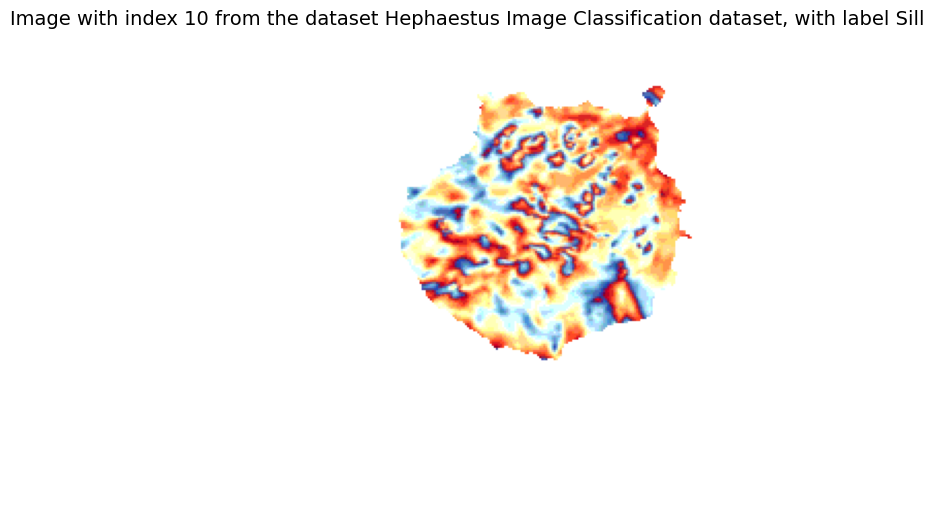

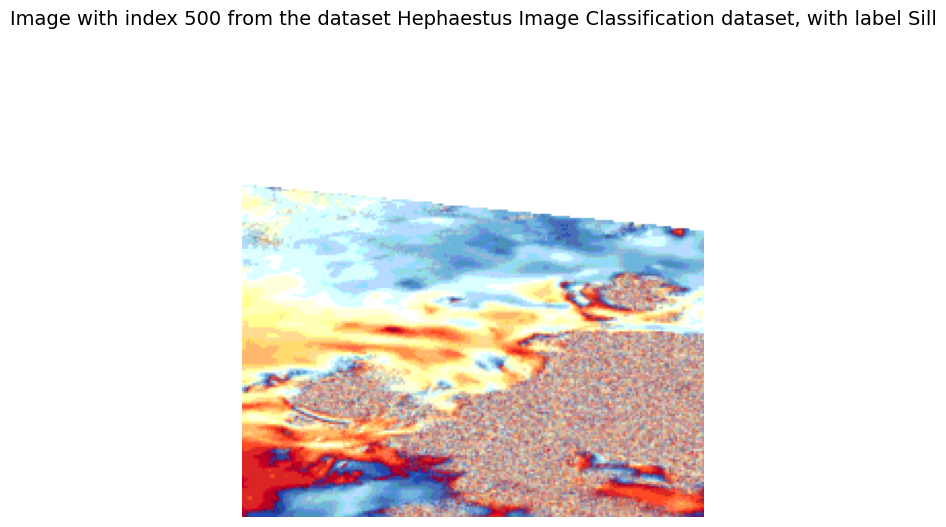

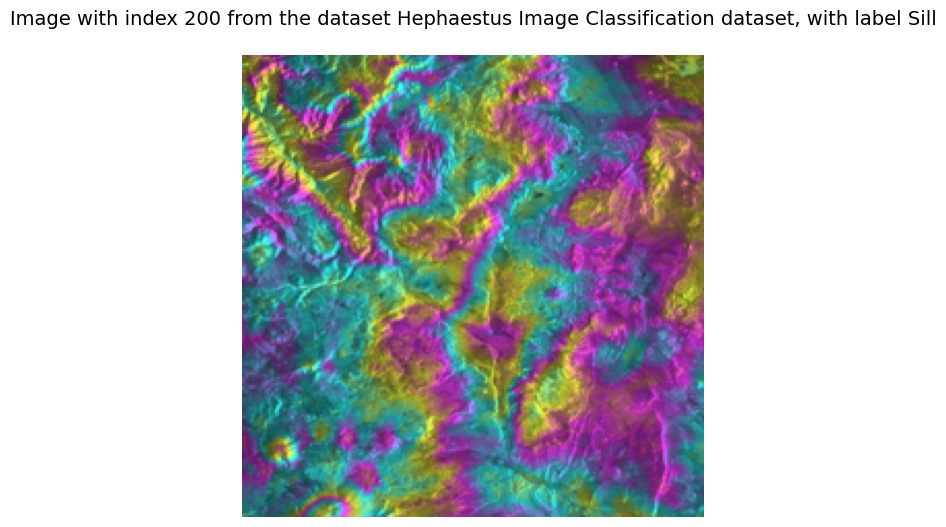

In [56]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(500)
fig3 = dataset.show_image(200)

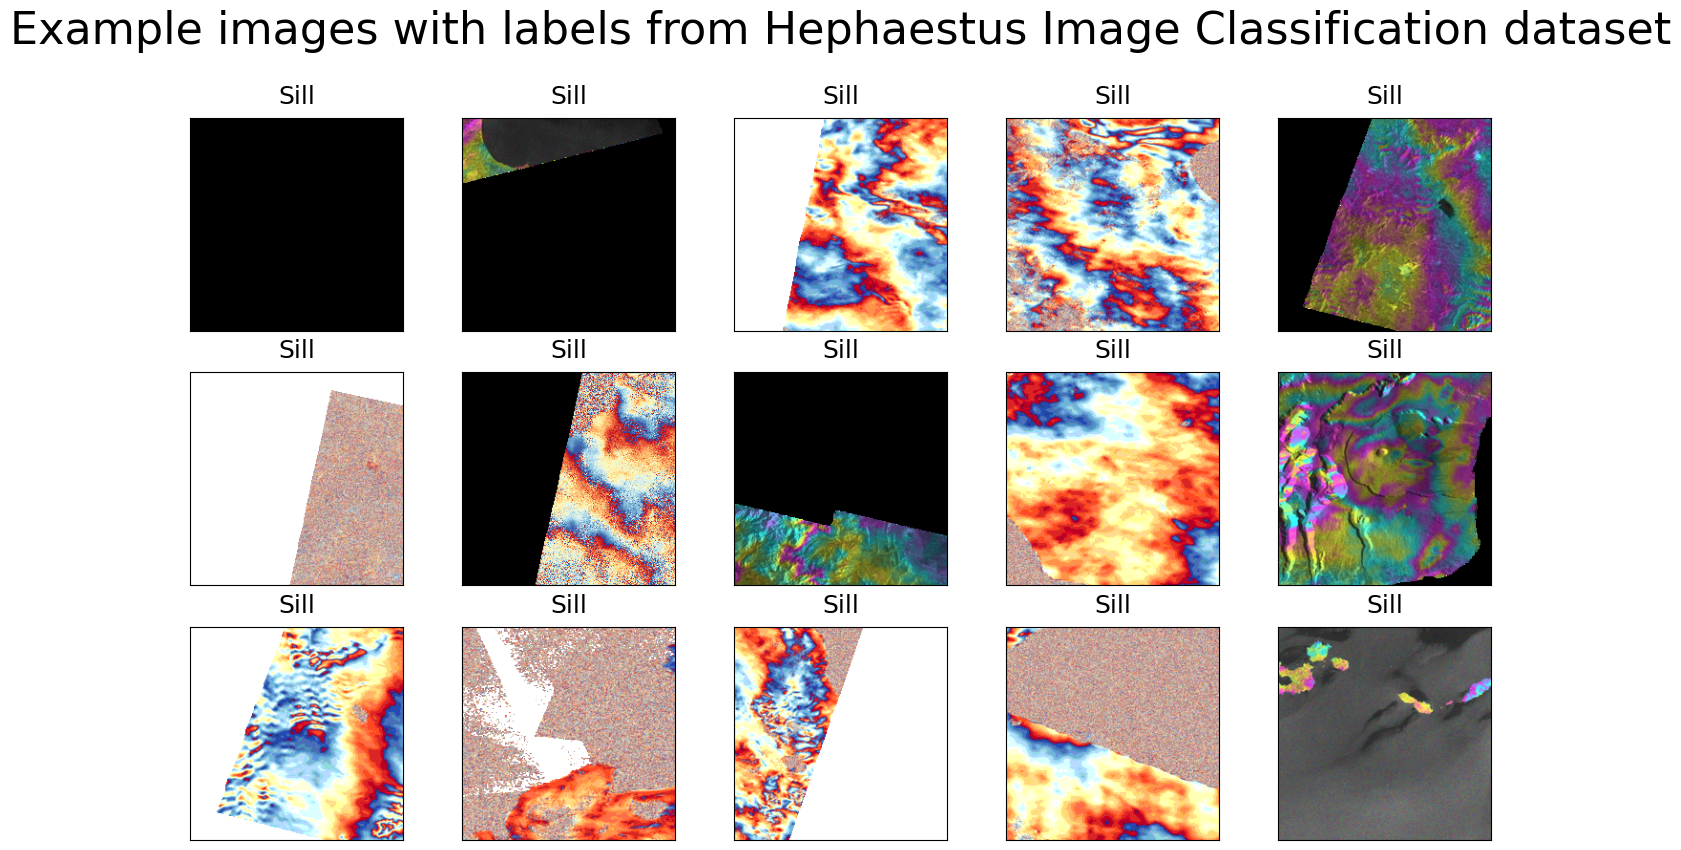

In [57]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [61]:
dataset.show_samples()

,File name,Label
0,0/14591_14.png,Sill
1,0/2320_4.png,Sill
2,0/1615_4.png,Sill
3,0/8270_3.png,Sill
4,0/4633_125.png,Sill
5,0/4580_110.png,Sill
6,0/17964_0.png,Sill
7,0/15109_7.png,Sill
8,0/1535_3.png,Sill
9,0/6979_6.png,Sill


In [62]:
dataset.data_distribution_table()

,Label,Count
0,Dyke,422
1,Earthquake,932
2,Mogi,355
3,Sill,171069
4,Spheriod,21
5,Unidentified,41
6,no-data,46


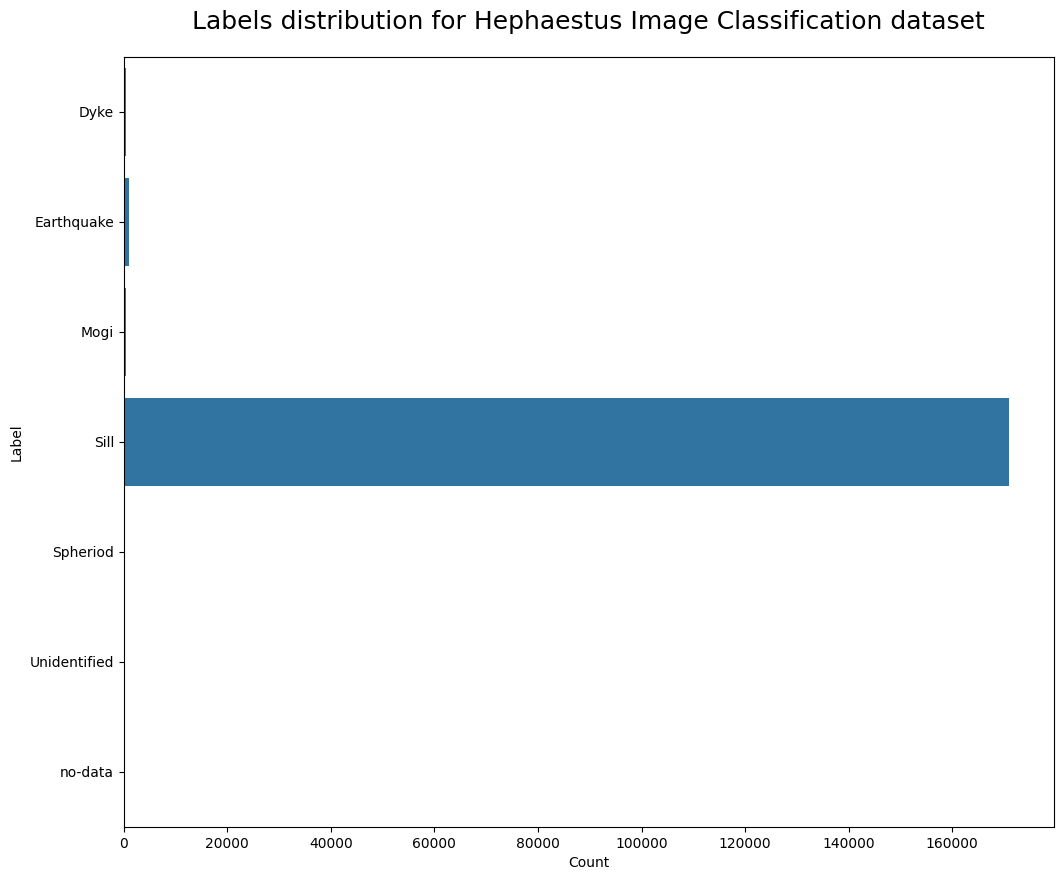

In [63]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/Hephaestus_classification/InSARLabelled/",
    "csv_file": "./data/Hephaestus_classification/InSARLabelled/train.csv",
}

train_dataset = HephaestusImageClassificationDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/Hephaestus_classification/InSARLabelled/",
    "csv_file": "./data/Hephaestus_classification/InSARLabelled/val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = HephaestusImageClassificationDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(172886, 21610)

## Setup and create the model for training

In [ ]:
epochs = 20
model_directory = "./data/experiments/Hephaestus_classification/"
model_config = {
    "num_classes": 7, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-05-28 12:23:38,539 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-05-28 12:23:38,751 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [6]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-05-28 12:23:43,830 INFO Starting training.
training: 100%|██████████| 5403/5403 [43:15<00:00,  2.08it/s]
2025-05-28 13:06:59,753 INFO epoch: 1, time: 2596, loss:  0.04771
testing on train set: 100%|██████████| 5403/5403 [18:49<00:00,  4.78it/s]
2025-05-28 13:25:51,496 INFO Accuracy:0.9916592436634545, Precision Micro:0.9916592436634545, Precision Macro:0.3855680592261534, Precision Weighted:0.9896794732249488, Precision per Class:[0.99321798 0.21259843 0.53760446 0.95555556 0.         0.
 0.        ], Recall Micro:0.9916592436634545, Recall Macro:0.2454074701013392, Recall Weighted:0.9916592436634545, Recall per Class:[0.99990062 0.07605634 0.45734597 0.18454936 0.         0.
 0.        ], F1_score Micro:0.9916592436634539, F1_score Macro:0.27316742388208914, F1_score Weighted:0.9891786691955422, F1_score per Class:[0.9965481  0.1120332  0.49423816 0.30935252 0.         0.
 0.        ]
testing on validation set: 100%|██████████| 676/676 [02:28<00:00,  4.54it/s]
2025-05-28 13:28:20

0.04718668370143836

## Test the model

In [ ]:

test_dataset_config = {
    "batch_size": 16,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/Hephaestus_classification/InSARLabelled/",
    "csv_file": "./data/Hephaestus_classification/InSARLabelled/test.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = HephaestusImageClassificationDataset(test_dataset_config)
model_path = "./data/experiments/Hephaestus_classification/checkpoint.pth.tar"
model.metrics = ["accuracy", "precision", "recall", "f1_score"]
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2025-05-29 06:40:26,447 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/Hephaestus_classification/checkpoint.pth.tar
2025-05-29 06:40:26,734 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/Hephaestus_classification/checkpoint.pth.tar at epoch 21
testing on test set: 100%|██████████| 1351/1351 [01:06<00:00, 20.31it/s]


[{'Accuracy': 0.991207774178621},
 {'Precision Micro': 0.991207774178621,
  'Precision Macro': 0.24643392324719662,
  'Precision Weighted': 0.986005405590849,
  'Precision per Class': array([0.99170413, 0.        , 0.        , 0.73333333, 0.        ,
         0.        , 0.        ])},
 {'Recall Micro': 0.991207774178621,
  'Recall Macro': 0.1708849941883028,
  'Recall Weighted': 0.991207774178621,
  'Recall per Class': array([0.99976639, 0.        , 0.        , 0.19642857, 0.        ,
         0.        , 0.        ])},
 {'F1_score Micro': 0.9912077741786205,
  'F1_score Macro': 0.18651115628157017,
  'F1_score Weighted': 0.9877869818443079,
  'F1_score per Class': array([0.99571894, 0.        , 0.        , 0.30985915, 0.        ,
         0.        , 0.        ])}]

## Predictions

2025-05-29 06:42:44,247 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/Hephaestus_classification/checkpoint.pth.tar
2025-05-29 06:42:44,546 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/Hephaestus_classification/checkpoint.pth.tar at epoch 21


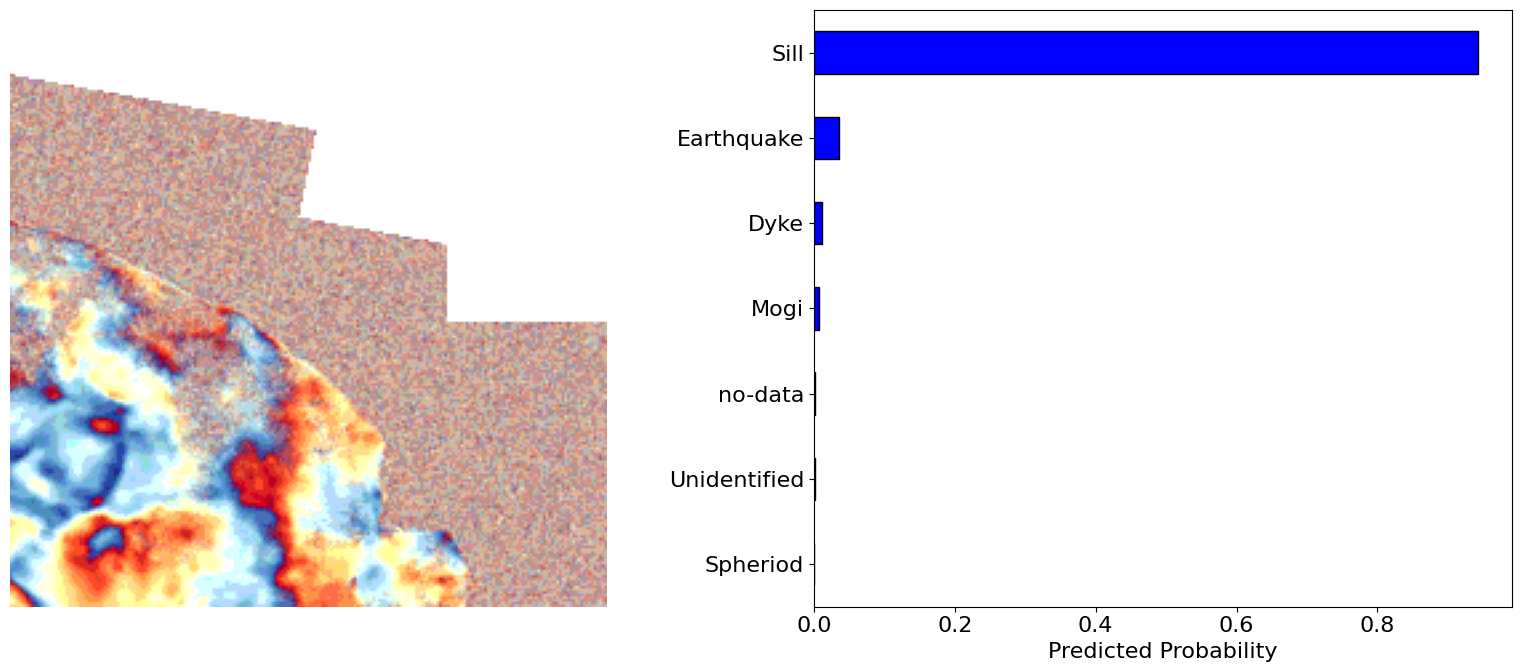

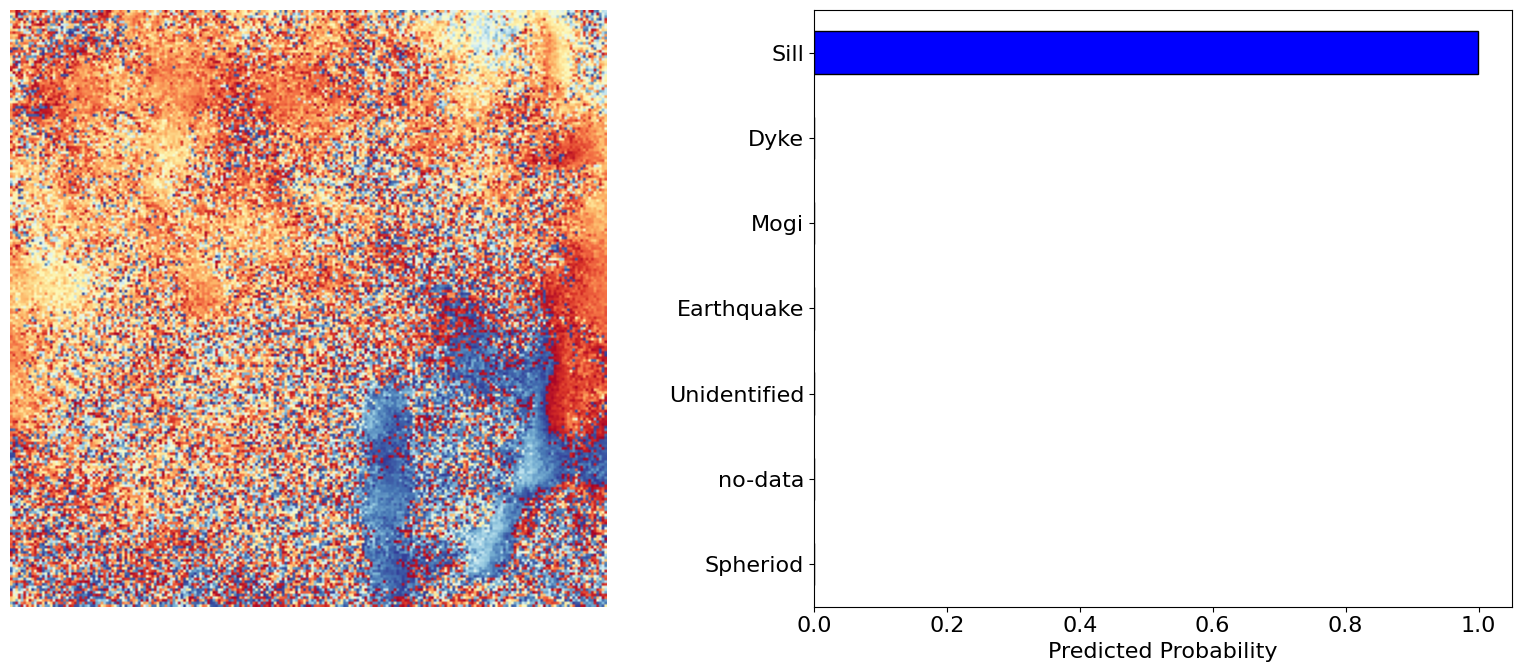

In [ ]:
labels = ["Sill","Mogi","Dyke","Earthquake","Spheriod","Unidentified","no-data"]
transform = ResizeCenterCropToTensor()

model_path = "./data/experiments/Hephaestus_classification/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('./data/Hephaestus_classification/InSARLabelled/0/6317_5.png')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/Hephaestus_classification/InSARLabelled/0/4724_103.png')
fig = model.predict_image(image, labels, transform)